In [ ]:
"""
Define of all the unit:
CGS system
P in units of eng * cm **-3
T_1 in unit of k
m in unit of g
rho in unit of g cm **-3
metallicity in units of solar metallicity
kB​=1.380649e−16 erg* K**-1
Problem: inconsistant kb definition
"""

'\nDefine of all the unit:\nCGS system\nP in units of eng * cm **-3\nT_1 in unit of k\nm in unit of g\nrho in unit of g cm **-3\nmetallicity in units of solar metallicity\nkB\u200b=1.380649e−16 erg* K**-1\nProblem: inconsistant kb definition\n'

In [ ]:
"""
Define of all constant:

"""
import numpy as np
mu = 0.62
muH = 1/0.75
kb = 1.380649e-16
gamma = 5/3
Z_solar = 0.02
mH = 1.673536 * 10**(-24)

In [ ]:
# shock transition
import numpy as np
def shock_tran(M_1, n_1, T_1):
  # presrure and bulk velocity
  # m here is the average mass of the gases rho_tot = n_tot * m
  P_1 = n_1* kb * T_1
  rho_1 = n_1*mH*mu
  u_1 = M_1 * (gamma * P_1 /(n_1*mH*mu))**.5 # M = u / v_sound
  # after shock density, tem, and bulk velocity
  rho_2 = rho_1 * ((gamma+1) * M_1**2)/((gamma - 1) * M_1**2 + 2)
  T_2 = ((gamma-1)* M_1** 2 + 2)*(2* gamma* M_1**2 - (gamma - 1))/((gamma + 1)**2 * M_1**2)*T_1
  u_2 = u_1 * rho_1/rho_2
  # return the ratio
  return u_2/u_1, rho_2/rho_1, T_2/T_1


In [ ]:
# adiabatic transition
def adi_tran(n1, T1, ka):
  """
  ka is p2/p1
  """
  p1 = kb * n1 * T1
  T2 = T1 * ka ** ((gamma-1)/gamma)
  n2 = n1 * ka ** (1/gamma)
  return n2, T2

In [ ]:
n2_adi, T2_adi = adi_tran(1e-3, 10**4.5, 10)
n2_adi_arrow = (T2_adi-10**4.5, n2_adi-1e-3)
n2_adi_2, T2_adi_2 = adi_tran(10**(-3.99) , 10**(5.22) , 10)
n2_adi_arrow_2= (T2_adi_2 -10**(5.22), n2_adi_2 -10**(-3.99) )
u2_shock_2, n2_shock_2, T2_shock_2 = shock_tran(5, 10**(-3.99),10**(5.22))
u2_shock, n2_shock, T2_shock = shock_tran(5, 1e-3, 10**4.5)
n2_shock_arrow = ((T2_shock-1) * 10**4.5, (n2_shock - 1) * 1e-3)
n2_shock_arrow_2 = ((T2_shock_2 -1) * 10**(5.22) , (n2_shock_2 - 1) * 10**(-3.99) )

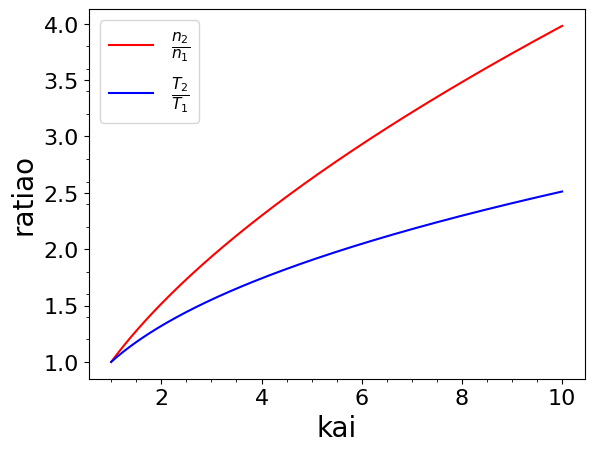

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
kai = np.linspace(1, 10, 10000)
n1 = 1e-3
T1 = 10**3
n2, T2 = adi_tran(n1, T1, kai)
plt.plot(kai, n2/n1, "r", label = r"$\frac{n_2}{n_1}$") #
plt.plot(kai, T2/T1, "b", label = r"$\frac{T_2}{T_1}$") #
plt.xlabel("kai", fontsize=20)
plt.ylabel("ratiao", fontsize=20)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
ax = plt.gca()
from matplotlib.ticker import MultipleLocator
ax.xaxis.set_minor_locator(MultipleLocator(0.5))
ax.yaxis.set_minor_locator(MultipleLocator(0.2))
plt.legend(fontsize=16)
plt.legend(fontsize=16)
plt.show()


In [ ]:
"""
set up
"""
import h5py
from scipy import interpolate
Cooling_File = "z_0.000.hdf5" ### From Wiersma et al. (2009) appropriate for z=0 UVB
f = h5py.File(Cooling_File, 'r')
i_X_He = -3
Metal_free   = f.get('Metal_free')
Total_Metals = f.get('Total_Metals')
log_Tbins    = np.array(np.log10(Metal_free['Temperature_bins']))
log_nHbins   = np.array(np.log10(Metal_free['Hydrogen_density_bins']))
Cooling_Metal_free   = np.array(Metal_free['Net_Cooling'])[i_X_He] ##### what Helium_mass_fraction to use    Total_Metals = f.get('Total_Metals')
Cooling_Total_Metals = np.array(Total_Metals['Net_cooling'])
HHeCooling           = interpolate.RectBivariateSpline(log_Tbins,log_nHbins, Cooling_Metal_free)
ZCooling             = interpolate.RectBivariateSpline(log_Tbins,log_nHbins, Cooling_Total_Metals)
Zs          = np.logspace(-2,1,31)
f.close()
Lambda_tab  = np.array([[[HHeCooling.ev(lT,ln)+Z*ZCooling.ev(lT,ln) for Z in Zs] for lT in log_Tbins] for ln in log_nHbins])
# cooling time is dependent on initial temp and the number density.
Lambda_z0 = interpolate.RegularGridInterpolator((log_nHbins,log_Tbins,Zs), Lambda_tab, bounds_error=False, fill_value=-1e-30)
# why there is out put of nan: is there anything wrong with the interpolation.

In [ ]:
"""
function of cooling function
"""
def tcool_P(T,n, metallicity):
  """
  cooling time function
  T in units of K
  P in units of K * cm **-3
  metallicity in units of solar metallicity
  returning time is log10(s)
  """
  T = np.where(T>10**8.98, 10**8.98, T)
  T = np.where(T<10**2, 10**2, T)
  nH_actual = np.clip(n*(mu/muH), None, 1)
  # n here is the total number density as well, but we convert total number density to hydrogen number density
  nH = np.where(nH_actual>100, 100, nH_actual)
  nH = np.where(nH<10**-8, 10**-8, nH)
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity))))


In [ ]:
"""
cooling time diff
"""
def time_diff(n1, T1, kai, metallicity):
  """
  n in unit of cm **-3
  T_1 in unit of k
  """
  n2, T2 = adi_tran(n1, T1, kai)
  tcool1 = tcool_P(T1, n1, metallicity)
  tcool2 = tcool_P(T2, n2, metallicity)
  diff = tcool2 - tcool1
  return diff

In [ ]:
print(time_diff(1e-3, 10**4.1, 2, 0.6))

-0.5768236250542582


/tmp/ipykernel_576/209421287.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity))))


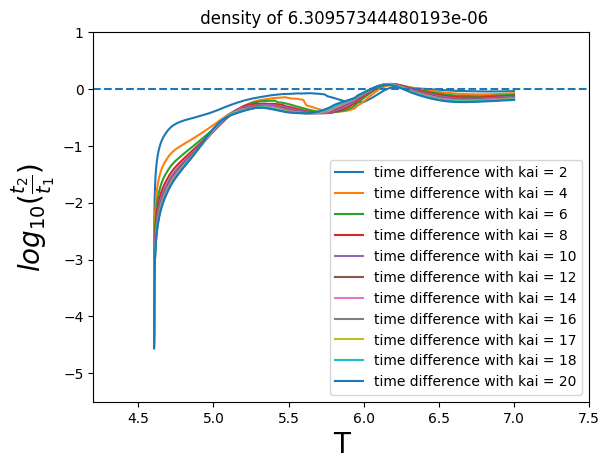

In [ ]:
T1 = np.linspace(4, 7, 10000)
kai = np.array((2, 4, 6, 8, 10, 12, 14, 16, 17, 18, 20))
n1  = 10**(-5.2)
metallicity = 0.3
for kai_i in kai:
  t_diff = time_diff(n1, 10**T1, kai_i, metallicity)
  plt.plot(T1, t_diff, label = f"time difference with kai = {kai_i}")
plt.xlim(4.2, 7.5)
plt.ylim(-5.5, 1)
plt.xlabel("T", fontsize=20)
plt.ylabel(r"$log_{10}(\frac{t_2}{t_1})$", fontsize=20)
plt.title(f" density of {n1}")
plt.legend(fontsize=10)
plt.axhline(y= 0, linestyle = "--")

/tmp/ipykernel_576/209421287.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity))))


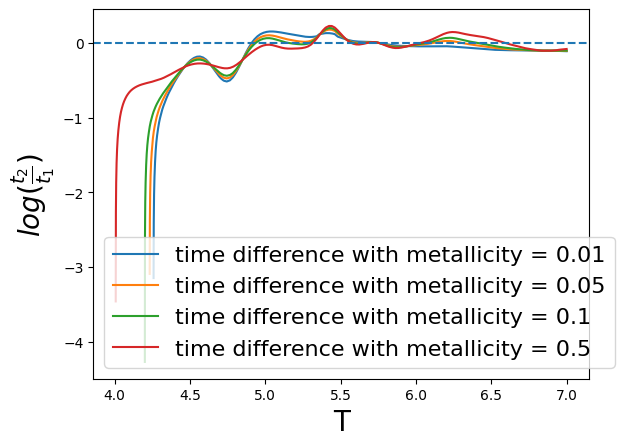

In [ ]:
T1 = np.linspace(4, 7, 10000)
kai = 2
n1  = 1e-3
metallicity = np.array((0.01, 0.05, 0.1, 0.5))
for mi in metallicity:
  t_diff = time_diff(n1, 10**T1, kai, mi)
  plt.plot(T1, t_diff, label = f"time difference with metallicity = {mi}")
plt.xlabel("T", fontsize=20)
plt.ylabel(r"$log(\frac{t_2}{t_1})$", fontsize=20)
plt.legend(fontsize=16)
plt.axhline(y= 0, linestyle = "--")

**Contour of Changing Kai**:

---



In [ ]:
"""Plot of tcool with varying kai"""
import numpy as np

T_range = np.linspace(4, 7, 5000)
n = 1e-4
metallicity = 0.3
data = {}
time_range = np.array((16.5, 16, 17))
for ti_val in time_range:
  pairs_M = []

  tcool_vals = tcool_P(10**T_range, n, metallicity)

  mask = (
        (tcool_vals - ti_val > np.log10(0.99)) &
        (tcool_vals - ti_val < np.log10(1.01))
      )

  t_col = T_range[mask]
  data[ti_val] = [] # Use ti_val as the key for the dictionary
  if t_col.size > 0:
        pairs_M.extend(list(t_col)) # Correctly extend with elements of t_col
        data[ti_val].append(pairs_M[0])
        data[ti_val].append(pairs_M[-1])
"""
Note that the line at 1e17 is close to hubble time, but is not exactly equal to hubble time
"""

/tmp/ipykernel_576/209421287.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity))))


'\nNote that the line at 1e17 is close to hubble time, but is not exactly equal to hubble time\n'

/tmp/ipykernel_576/209421287.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity))))
/tmp/ipykernel_576/1889821536.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=12, loc = 'lower right')


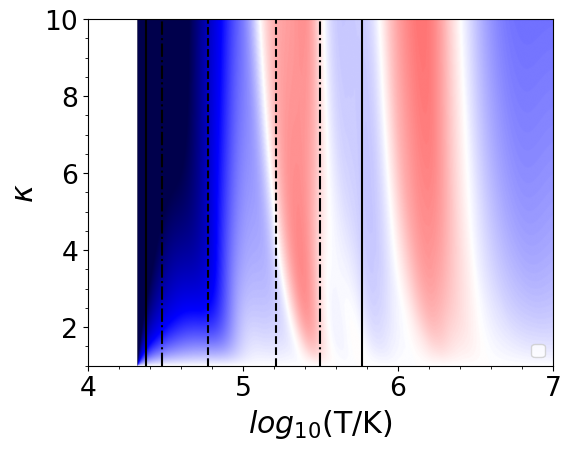

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
# Create 1D coordinate arrays
kai_range = np.linspace(1, 10, 1000)
T_range = np.linspace(4, 7, 1000)
n = 1e-4
metallicity = 0.3
# Create coordinate grid
T , Kai= np.meshgrid(T_range, kai_range)
Z = time_diff(n, 10**T, Kai, metallicity)
colors = ["yellow", "black", "red"]   # negative → zero → positive
cmap = mcolors.LinearSegmentedColormap.from_list("custom", colors)
A = np.max(np.abs(Z))
# Plot heatmap
fig = plt.figure(figsize=(6, 4.5))
scale = 6 / 2.5
plt.rcParams.update({
    "axes.titlesize":  9 * scale,
    "axes.labelsize":  9 * scale,
    "xtick.labelsize": 8 * scale,
    "ytick.labelsize": 8 * scale,
    "legend.fontsize": 8 * scale,
})
plt.imshow(
    Z,
    extent=[T_range.min(), T_range.max(), kai_range.min(), kai_range.max()],
    origin='lower',
    aspect='auto',
    cmap= 'seismic', # diverging colormap
    vmin=-1,
    vmax=1
)
T_7_0 = data[17][0]
T_7_1 = data[17][1]
T_6_0 = data[16][0]
T_6_1 = data[16][1]
T_5_0 = data[16.5][0]
T_5_1 = data[16.5][1]
#T_4_0 = data[14][0]
#T_4_1 = data[14][1]
plt.axvline(x = T_7_0, color =  "black", linestyle = "-")# , label =  r"$t_{cool} = 10^{17}$")
plt.axvline(x = T_7_1, color =  "black", linestyle = "-")
plt.axvline(x = T_6_0, color =  "black", linestyle = "--") #, label = r"$t_{cool} = 10^{16}$")
plt.axvline(x = T_6_1, color =  "black", linestyle = "--" )
plt.axvline(x = T_5_0, color =  "black", linestyle="-.")#  label = r"$t_{cool} = 10^{15}$")
plt.axvline(x = T_5_1, color =  "black", linestyle="-.")
#plt.axvline(x = T_4_0, color =  "black", linestyle=(0, (5, 2, 5, 2, 5, 2, 1, 2)), label = r"t = $10^{14}$")
#plt.axvline(x = T_4_1, color =  "black", linestyle=(0, (5, 2, 5, 2, 5, 2, 1, 2)), label = r"t = $10^{14}$")
#plt.colorbar(label=r"$log(\frac{t_2}{t_1})$")
plt.xlabel(r"$log_{10}(\mathrm{T/K})$")
plt.ylabel(r"$\kappa$")
# plt.title(r"Cooling time with varying $\kappa$ & T")
ax = plt.gca()
ax.xaxis.set_minor_locator(MultipleLocator(0.2))
ax.yaxis.set_minor_locator(MultipleLocator(0.5))
plt.legend(fontsize=12, loc = 'lower right')
plt.show()

**Contour of Changing density**:

---





In [ ]:
"""
plot of tcool = t_H varying n
"""
import numpy as np

T_range = np.linspace(4, 7, 5000)
n_range = np.linspace(-6, 0, 5000)

metallicity = 0.3
t_H = 1e17
log_tH = np.log10(t_H)

pairs_n = []

for ti in T_range:
    tcool_vals = tcool_P(10**ti, 10**n_range, metallicity)

    mask = (
        (tcool_vals - log_tH >= np.log10(0.999)) &
        (tcool_vals - log_tH < np.log10(1.001))
    )

    n_col = n_range[mask]

    if n_col.size > 0:
        pairs_n.extend([(ti, ni) for ni in n_col])
T_n_H = [p[0] for p in pairs_n]
n_H = [p[1] for p in pairs_n]

/tmp/ipykernel_576/209421287.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity))))


In [ ]:
from scipy.interpolate import interp1d
bottom_func = interp1d(T_n_H, n_H, kind = 'cubic', fill_value="extrapolate")

In [ ]:
from scipy.optimize import root_scalar
t_range = np.array((1e16, 10**(16.5), 1e14, 1e15))
T_range = np.linspace(4, 7, 2000)
metallicity = 0.3
data = {}
for ti in t_range:
    data[ti] = []
    for Ti in T_range:
        def tcool_midel(x):
          return tcool_P(10**Ti, 10**x, metallicity) - np.log10(ti)
        if tcool_midel(bottom_func(Ti))*tcool_midel(0) <= 0:
          solution = root_scalar(tcool_midel, bracket = [bottom_func(Ti), 0], method='brentq')
          data[ti].append((Ti, solution.root))
T0, n_0 = zip(*data[1e16])
T1, n_1 = zip(*data[10**(16.5)])
T2, n_2 = zip(*data[1e14])
T3, n_3 = zip(*data[1e15])

/tmp/ipykernel_576/209421287.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity))))
/tmp/ipykernel_576/62065559.py:44: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=12, loc = 'lower right')


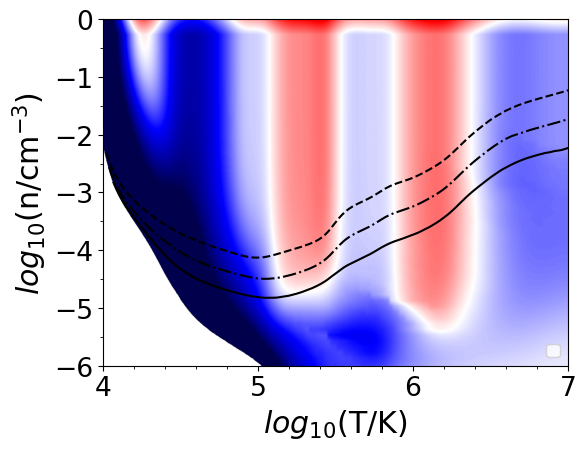

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
# Create 1D coordinate arrays
n_range = np.linspace(-6, 0, 1000)
T_range = np.linspace(4, 7, 1000)
kai = 10
metallicity = 0.3
# Create coordinate grid
T , N= np.meshgrid(T_range, n_range)
Z = time_diff(10**N, 10**T, kai, metallicity)
A = np.max(np.abs(Z))
fig = plt.figure(figsize=(6, 4.5))
scale = 6 / 2.5
plt.rcParams.update({
    "axes.titlesize":  9 * scale,
    "axes.labelsize":  9 * scale,
    "xtick.labelsize": 8 * scale,
    "ytick.labelsize": 8 * scale,
    "legend.fontsize": 8 * scale,
})
# Plot heatmap
plt.imshow(
    Z,
    extent=[T_range.min(), T_range.max(), n_range.min(), n_range.max()],
    origin='lower',
    aspect='auto',
    cmap='seismic', # diverging colormap
    vmin=-1,
    vmax=1
)
plt.plot(T_n_H, n_H, "black", linestyle = "-")# , label = r"$t_{cool} = 10^{17}$")
plt.plot(T0, n_0, "black", linestyle = "--" )# , label = r"$t_{cool} = 10^{16}$")
plt.plot(T1, n_1, "black", linestyle="-.")#, label = r"$t_{cool} = 10^{15}$")
# plt.plot(T2, n_2, "black", linestyle=(0, (5, 2, 5, 2, 5, 2, 1, 2)), label = r"$t_{cool} = 10^{14}$")
# plt.colorbar(label=r"$log(\frac{t_2}{t_1})$")
plt.xlabel(r"$log_{10}(\mathrm{T/K})$")
plt.ylabel(r"$log_{10}(\mathrm{n}/\mathrm{cm}^{-3})$")
# plt.title(r"Cooling time with varying n & T")
ax = plt.gca()
ax.xaxis.set_minor_locator(MultipleLocator(0.2))
ax.yaxis.set_minor_locator(MultipleLocator(0.5))
plt.legend(fontsize=12, loc = 'lower right')
plt.show()

**Contour of Kai, T, n**

---



/tmp/ipykernel_576/4268953974.py:27: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('rainbow', len(bounds)-1)


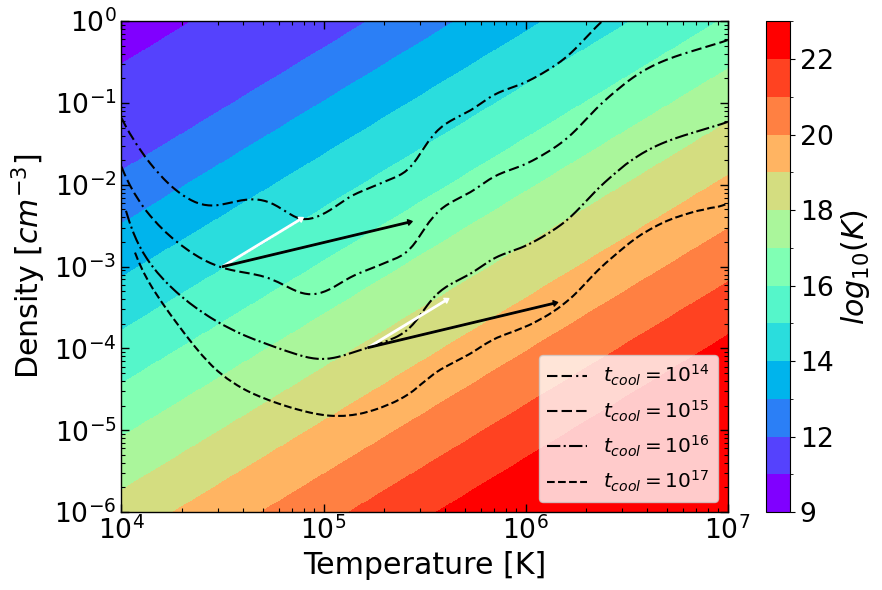

In [ ]:
from matplotlib.lines import Line2D
import matplotlib.colors as colors
def kai_func(T, n):
  return np.log(T/n**(2/3))
import matplotlib.ticker as ticker
fig, ax = plt.subplots(figsize=(9, 6))


n1_0 = 1e-3
T1_0 = 10**4.5
plt.rcParams.update({
    "axes.titlesize":  9 * scale,
    "axes.labelsize":  9 * scale,
    "xtick.labelsize": 8 * scale,
    "ytick.labelsize": 8 * scale,
    "legend.fontsize": 6 * scale,
})
n2_0 = 10**(-3.99)
T2_0 = 10**(5.22)
n_range = 10** np.linspace(-6, 0, 1000)
T_range = 10** np.linspace(4, 7, 1000)
T , N= np.meshgrid(T_range, n_range)
Z = kai_func(T, N)
A_max = np.max(np.abs(Z))
A_min = np.min(np.abs(Z))
bounds = [9, 10, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 24 ]
cmap = plt.cm.get_cmap('rainbow', len(bounds)-1)
norm = colors.BoundaryNorm(bounds, cmap.N)
# Plot heatmap
plt.pcolormesh(
    T, N, Z,
    cmap= cmap,
    norm = norm
)
plt.plot(10**np.array(T2), 10**np.array(n_2), "black", linestyle=(0, (5, 2, 5, 2, 1, 2)), label = r"$t_{cool} = 10^{14}$")
plt.plot(10**np.array(T3), 10**np.array(n_3), "black", linestyle=(0, (5, 2, 5, 2, 5, 2, 1, 2)), label = r"$t_{cool} = 10^{15}$")
plt.plot(10**np.array(T0), 10**np.array(n_0), "black", linestyle = "-." , label = r"$t_{cool} = 10^{16}$")
plt.plot(10**np.array(T_n_H), 10**np.array(n_H), "black", linestyle = "--", label = "$t_{cool} = 10^{17}$")
plt.colorbar(label=r"$log_{10}(K)$")
aid_arrow0 = n2_adi_arrow[0]
aid_arrow1 = n2_adi_arrow[1]
shock_arrow0 = n2_shock_arrow[0]
shock_arrow1 = n2_shock_arrow[1]
aid_arrow2 = n2_adi_arrow_2[0]
aid_arrow3 = n2_adi_arrow_2[1]
shock_arrow2 = n2_shock_arrow_2[0]
shock_arrow3 = n2_shock_arrow_2[1]
ax.annotate('', xy=(T1_0 + aid_arrow0, n1_0 + aid_arrow1), xytext=(T1_0, n1_0),
            arrowprops=dict(facecolor='white', edgecolor='white', width=1, headwidth=4, headlength=3))
ax.annotate('', xy=(T1_0 + shock_arrow0, n1_0 + shock_arrow1), xytext=(T1_0, n1_0),
            arrowprops=dict(facecolor='black', edgecolor='black', width=1, headwidth=4, headlength=3))
ax.annotate('', xy=(T2_0 + aid_arrow2, n2_0 + aid_arrow3), xytext=(T2_0, n2_0),
            arrowprops=dict(facecolor='white', edgecolor='white', width=1, headwidth=4, headlength=3))
ax.annotate('', xy=(T2_0 + shock_arrow2, n2_0 + shock_arrow3), xytext=(T2_0, n2_0),
            arrowprops=dict(facecolor='black', edgecolor='black', width=1, headwidth=4, headlength=3))
adi_proxy = Line2D([0], [0], color='white', lw=2, label='adi arrow',  markeredgecolor='black')
shock_proxy = Line2D([0], [0], color='black', lw=2, label='shock arrow')
ax.set_xscale('log')
ax.set_yscale('log')

# --- Axis limits (adjust to your data) ---
ax.set_ylim(1e-6, 1)
ax.set_xlim(1e4, 1e7)

# --- Tick styling: inward, on all sides ---
ax.tick_params(axis='both', which='both', direction='in', top=True, right=True)
ax.tick_params(axis='both', which='major', length=6, width=1)
ax.tick_params(axis='both', which='minor', length=3, width=0.8)

# --- Log-scale minor ticks (the small unlabeled ticks between decades) ---
ax.xaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs='auto', numticks=100))
ax.yaxis.set_minor_locator(ticker.LogLocator(base=10.0, subs='auto', numticks=100))

# --- Clean box frame (spines) ---
for spine in ax.spines.values():
    spine.set_linewidth(1)

# --- Labels ---
ax.set_xlabel('Temperature [K]')
ax.set_ylabel(r'Density [$cm^{-3}$]')
plt.tight_layout()
handles, labels = ax.get_legend_handles_labels()
handles += [adi_proxy, shock_proxy]
labels += ['adi arrow', 'shock arrow']
# plt.title("Entropy Proxy of Varying Temperature and Density")
plt.legend(loc='lower right')
plt.show()
# make another arrow here


**Contour of Changing metallicity**:

---



In [ ]:
'''
Plot of tcool = t_H varying metallicity
'''
import numpy as np

T_range = np.linspace(4, 7, 5000)
m_range = np.linspace(0.01, 1, 5000)

n = 1e-4
t_H = 1e17
log_tH = np.log10(t_H)

pairs_m = []

for ti in T_range:
    tcool_vals = tcool_P(10**ti, n, m_range)

    mask = (
        (tcool_vals - log_tH >= np.log10(0.999)) &
        (tcool_vals - log_tH <= np.log10(1.001))
    )

    m_col = m_range[mask]

    if m_col.size > 0:
        pairs_m.extend([(ti, Mi) for Mi in m_col])
T_m = [p[0] for p in pairs_m]
m = [p[1] for p in pairs_m]

/tmp/ipykernel_576/209421287.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity))))


In [ ]:
from scipy.interpolate import interp1d
import numpy as np

# Ensure T_m and m are numpy arrays for consistent behavior
T_m_arr = np.array(T_m)
m_arr = np.array(m)

# Combine T_m_arr and m_arr into a 2D array
combined_data = np.column_stack((T_m_arr, m_arr))

# Sort the combined data by the first column (T_m_arr values)
sorted_combined_data = combined_data[combined_data[:, 0].argsort()]

# Extract unique T_m_arr values and their corresponding m_arr values
# np.unique with return_index will give the unique values and the indices of their first occurrence
unique_T_m_arr, unique_indices = np.unique(sorted_combined_data[:, 0], return_index=True)
unique_m_arr = sorted_combined_data[unique_indices, 1]

bottom_func_2 = interp1d(unique_T_m_arr, unique_m_arr, kind='linear', fill_value="extrapolate")

In [ ]:
from scipy.optimize import root_scalar
t_range = np.array((10**(16), 10**(16.5)))
T_range = np.linspace(4, 7, 2000)
n = 1e-4
data = {}
for ti in t_range:
    data[ti] = []
    for Ti in T_range:
        def tcool_midel(x):
          return tcool_P(10**Ti, n, x) - np.log10(ti)
        if tcool_midel(bottom_func_2(Ti))*tcool_midel(1) <= 0:
          solution = root_scalar(tcool_midel, bracket = [bottom_func_2(Ti), 1], method='brentq')
          data[ti].append((Ti, solution.root))
T0, m_0 = zip(*data[10**(16)])
T1, m_1 = zip(*data[10**(16.5)])
#T2, m_2 = zip(*data[1e14])
# Also there is no value for t = 1e14

/tmp/ipykernel_576/209421287.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity))))


/tmp/ipykernel_576/209421287.py:18: RuntimeWarning: invalid value encountered in log10
  return np.log10((1./(gamma-1.)) * (muH/mu) * kb * T / ( nH_actual * Lambda_z0((np.log10(nH),np.log10(T), metallicity))))


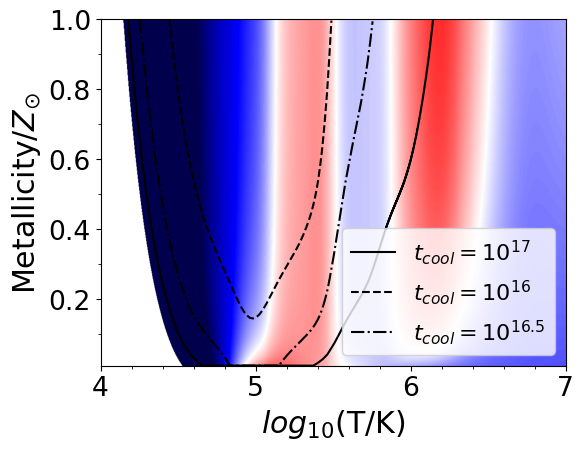

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
# Create 1D coordinate arrays
metal_range = np.linspace(0.01, 1, 1000)
T_range = np.linspace(4, 7, 1000)
kai = 10
n = 1e-4
# Create coordinate grid
T , Metallicity= np.meshgrid(T_range, metal_range)
Z = time_diff(n, 10**T, kai, Metallicity)
A = np.max(np.abs(Z))
fig = plt.figure(figsize=(6, 4.5))
# Plot heatmap
scale = 6 / 2.5
plt.rcParams.update({
    "axes.titlesize":  9 * scale,
    "axes.labelsize":  9 * scale,
    "xtick.labelsize": 8 * scale,
    "ytick.labelsize": 8 * scale,
    "legend.fontsize": 8 * scale,
})
plt.imshow(
    Z,
    extent=[T_range.min(), T_range.max(), metal_range.min(), metal_range.max()],
    origin='lower',
    aspect='auto',
    cmap='seismic', # diverging colormap
    vmin=-1,
    vmax=1
)
plt.plot(T_m_arr, m_arr, "black", linestyle = "-", label = r"$t_{cool} = 10^{17}$")
plt.plot(T0, m_0, "black", linestyle = "--" , label = r"$t_{cool} = 10^{16}$")
plt.plot(T1, m_1, "black", linestyle="-.", label = r"$t_{cool} = 10^{16.5}$")
# plt.plot(T2, 10**m_2, "black", linestyle=(0, (5, 2, 5, 2, 5, 2, 1, 2)), label = r"t = $10^{14}$")
# plt.colorbar(label=r"$log(\frac{t_2}{t_1})$")
plt.xlabel(r"$log_{10}(\mathrm{T}/ \mathrm{K})$")
plt.ylabel(r"$\mathrm{Metallicity}$/$Z_{\odot}$")
# plt.title(r"Cooling time with varying Metallicity & T")
ax = plt.gca()
ax.xaxis.set_minor_locator(MultipleLocator(0.2))
ax.yaxis.set_minor_locator(MultipleLocator(0.1))
plt.legend(fontsize=16, loc ='lower right')
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


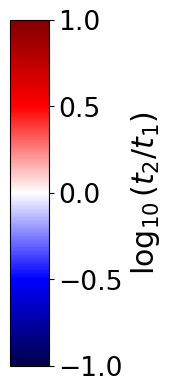

In [ ]:
import matplotlib as mpl

fig, cax = plt.subplots(figsize=(.5, 4.5), constrained_layout=True)

norm = mpl.colors.Normalize(vmin=-1, vmax=1)
sm = mpl.cm.ScalarMappable(norm=norm, cmap='seismic')

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label(r'$\log_{10}(t_2/t_1)$')
# legend:z_sun, t_cool, cleaning up plot